<a href="https://colab.research.google.com/github/vishwa24816/Montecarlo/blob/main/Montecarlo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# =============================================================================
# SECTION 1: INPUTS
# Edit only this cell. All other cells read from these values.
# =============================================================================

# --- Asset selection -------------------------------------------------------
# Single ticker as a string, e.g. "AAPL".
# A list, e.g. ["AAPL", "MSFT", "SPY"], turns on comparison mode (Section 10).
ticker = "AAPL"

# --- Capital and horizon ---------------------------------------------------
start_capital = 10_000            # starting investment, in USD
years = 30                        # simulation horizon, in years (must be >= 1)
steps_per_year = 252              # 252 = trading days; 1 = annual steps

# --- Simulation size -------------------------------------------------------
n_paths = 10_000                  # number of simulated paths (must be >= 1000)
seed = 42                         # random seed for reproducibility

# --- Calibration window ----------------------------------------------------
history_years = 10                # lookback window for estimating mu and sigma

# --- Optional overrides (None = use historical estimate) -------------------
# Annualized arithmetic mean return, e.g. 0.08 for 8% per year.
mu_override = None
# Annualized volatility, e.g. 0.20 for 20% per year. Must be >= 0 if set.
sigma_override = None

# --- Shock distribution ----------------------------------------------------
# "normal"    : Gaussian shocks (standard GBM)
# "student_t" : fat-tailed shocks, rescaled to match sigma
shock_model = "normal"
df = 5                            # degrees of freedom for student_t (must be > 2)

# --- Risk measures ---------------------------------------------------------
risk_free_rate = 0.04             # annual, used only for Sharpe-style comparison
loss_threshold = start_capital    # terminal value below this counts as a "loss"
percentiles = [5, 10, 25, 50, 75, 90, 95]   # percentiles reported in Section 7

In [2]:
# =============================================================================
# SECTION 2: DATA AND CALIBRATION
# Downloads adjusted closes, estimates mu and sigma, and derives the GBM drift.
# =============================================================================

import warnings
import numpy as np
import pandas as pd

MIN_OBS = 252  # warn if fewer daily observations than this remain

def download_prices(symbol, years_back):
    """Return a Series of adjusted closing prices, or None if the download fails."""
    try:
        import yfinance as yf
        end = pd.Timestamp.today().normalize()
        start = end - pd.DateOffset(years=years_back)
        data = yf.download(
            symbol, start=start, end=end,
            auto_adjust=True,      # closes are split- and dividend-adjusted
            progress=False, threads=False,
        )
        if data is None or data.empty:
            return None
        close = data["Close"]
        if isinstance(close, pd.DataFrame):   # newer yfinance returns MultiIndex columns
            close = close.iloc[:, 0]
        return close.dropna()
    except Exception as exc:
        print(f"  Download error for {symbol}: {exc}")
        return None


def synthetic_prices(years_back, seed_value=0):
    """
    Clearly labeled fallback series, used only when the download fails.
    Built as a GBM with arithmetic mean 8% and volatility 20%.
    These numbers are NOT real market data.
    """
    rng = np.random.default_rng(seed_value)
    n = years_back * 252
    # Log drift per step = (mu - sigma^2/2) / 252, so the arithmetic mean is 8%
    log_r = rng.normal((0.08 - 0.5 * 0.20**2) / 252, 0.20 / np.sqrt(252), n)
    idx = pd.bdate_range(end=pd.Timestamp.today().normalize(), periods=n)
    return pd.Series(100 * np.exp(np.cumsum(log_r)), index=idx)


def calibrate(symbol):
    """
    Estimate the GBM parameters for one ticker.

    Returns a dict with:
      mu_arith     annualized arithmetic mean return
      sigma        annualized volatility
      growth       annualized log drift, mu - sigma^2/2 (volatility drag)
      growth_step  per-step log drift used by the simulator
      hist_log_returns  daily log returns, kept for the diagnostics in Section 9
    """
    prices = download_prices(symbol, history_years)
    source = "yfinance"

    if prices is None or len(prices) < 2:
        warnings.warn(f"{symbol}: download failed. Using SYNTHETIC demo data.")
        print(f"WARNING: could not download {symbol}. Using labeled SYNTHETIC demo data.")
        prices = synthetic_prices(history_years)
        source = "SYNTHETIC DEMO"

    # Daily log returns: r_t = ln(P_t / P_{t-1}); drop the first NaN
    log_ret = np.log(prices / prices.shift(1)).dropna().to_numpy()

    if len(log_ret) < MIN_OBS:
        warnings.warn(
            f"{symbol}: only {len(log_ret)} observations after cleaning "
            f"(fewer than {MIN_OBS}). Estimates will be unreliable."
        )

    # Annualized arithmetic mean. Estimate the log-return mean, then add back
    # half the variance so that mu is the arithmetic (not log) mean return.
    mu_hist = (log_ret.mean() + 0.5 * log_ret.var(ddof=1)) * steps_per_year
    sigma_hist = log_ret.std(ddof=1) * np.sqrt(steps_per_year)

    mu_arith = mu_override if mu_override is not None else mu_hist
    sigma = sigma_override if sigma_override is not None else sigma_hist

    # Volatility-drag correction (Jensen's inequality): the median path grows
    # at mu - sigma^2/2, not at the arithmetic mean mu.
    growth = mu_arith - sigma**2 / 2
    growth_step = growth / steps_per_year

    return dict(
        symbol=symbol,
        source=source,
        n_obs=len(log_ret),
        mu_arith=mu_arith,
        sigma=sigma,
        growth=growth,
        growth_step=growth_step,
        hist_log_returns=log_ret,
    )


# Run calibration for every ticker in the input cell
tickers = ticker if isinstance(ticker, list) else [ticker]
calib = {t: calibrate(t) for t in tickers}

c0 = calib[tickers[0]]
print(f"{c0['symbol']} [{c0['source']}]   observations: {c0['n_obs']}")
print(f"  mu (arithmetic, annual)   = {c0['mu_arith']:.4f}")
print(f"  sigma (annual)            = {c0['sigma']:.4f}")
print(f"  growth = mu - sigma^2/2   = {c0['growth']:.4f}")
print(f"  growth per step           = {c0['growth_step']:.6f}")

AAPL [yfinance]   observations: 2511
  mu (arithmetic, annual)   = 0.3024
  sigma (annual)            = 0.2911
  growth = mu - sigma^2/2   = 0.2601
  growth per step           = 0.001032


In [3]:
# =============================================================================
# SECTION 3: RANDOM SHOCK GENERATION
# Draws per-step log-return shocks for every path.
# Memory note: if the full matrix would exceed about 500 million elements,
# the simulation is run in chunks of paths (see Section 4), so the complete
# matrix is never held in memory at once.
# =============================================================================

import numpy as np

# Number of simulation steps over the whole horizon
N_STEPS = int(years * steps_per_year)

# Element count above which we chunk the simulation over paths
CHUNK_THRESHOLD = 500_000_000

# Single seeded generator for all draws. Never use np.random.seed.
rng = np.random.default_rng(seed)


def draw_log_returns(rng, n_rows, growth_step, sigma):
    """
    Draw an (n_rows, N_STEPS) matrix of per-step log returns.

    Normal model:
        r ~ Normal(loc = growth_step, scale = sigma / sqrt(steps_per_year))

    Student-t model:
        A t variable with df > 2 has variance df / (df - 2). Multiplying by
        sqrt((df - 2) / df) gives unit variance. Scaling by the target step
        standard deviation then matches sigma exactly, while keeping fat tails.
    """
    step_scale = sigma / np.sqrt(steps_per_year)

    if shock_model == "normal":
        return rng.normal(loc=growth_step, scale=step_scale, size=(n_rows, N_STEPS))

    # shock_model == "student_t"
    t_raw = rng.standard_t(df, size=(n_rows, N_STEPS))
    t_unit_var = t_raw * np.sqrt((df - 2) / df)   # variance now 1
    return growth_step + step_scale * t_unit_var


# Report the size of the full matrix and whether chunking will be used
total_elements = n_paths * N_STEPS
uses_chunks = total_elements > CHUNK_THRESHOLD

print(f"Shock model:      {shock_model}" + (f" (df = {df})" if shock_model == "student_t" else ""))
print(f"Steps:            {N_STEPS:,}  ({years} years x {steps_per_year} steps/year)")
print(f"Full matrix:      {n_paths:,} x {N_STEPS:,} = {total_elements:,} elements")
print(f"Processing mode:  {'chunked over paths' if uses_chunks else 'single matrix in memory'}")

Shock model:      normal
Steps:            7,560  (30 years x 252 steps/year)
Full matrix:      10,000 x 7,560 = 75,600,000 elements
Processing mode:  single matrix in memory


In [4]:
# =============================================================================
# SECTION 4: PATH ACCUMULATION
# Turns per-step log returns into price paths:
#   paths[:, t] = start_capital * exp(sum of log returns up to step t)
# A column of start_capital is prepended so that t = 0 is included.
# Large runs are generated in chunks of paths (see Section 3 for the rule).
# =============================================================================

import numpy as np

# Time axis in years, one value per column of the path matrix (t = 0 included)
time_years = np.linspace(0, years, N_STEPS + 1)


def simulate_chunk(rng, n_rows, growth_step, sigma):
    """
    Simulate n_rows paths.

    Returns an array of shape (n_rows, N_STEPS + 1):
      column 0 is start_capital (t = 0),
      column k is the value after k steps.
    """
    log_ret = draw_log_returns(rng, n_rows, growth_step, sigma)   # Section 3
    cum_log = np.cumsum(log_ret, axis=1)                          # running sum over time
    paths = start_capital * np.exp(cum_log)

    head = np.full((n_rows, 1), float(start_capital))             # t = 0 column
    return np.hstack([head, paths])


def simulate_full(c):
    """Simulate all n_paths at once. Used when the matrix fits in memory."""
    rng_run = np.random.default_rng(seed)
    return simulate_chunk(rng_run, n_paths, c["growth_step"], c["sigma"])


# Build the path matrix for the primary ticker when it fits in memory.
# When chunking is needed, this is skipped here; Section 6 handles it chunk by chunk.
c_primary = calib[tickers[0]]

if not uses_chunks:
    paths_primary = simulate_full(c_primary)
    print(f"Path matrix shape: {paths_primary.shape}  (paths x time points)")
    print(f"Time axis:         {time_years[0]:.0f} to {time_years[-1]:.0f} years, "
          f"{len(time_years):,} points")
    print(f"Start value check: column 0 = {paths_primary[0, 0]:,.0f}")
else:
    paths_primary = None
    print("Path matrix not built in memory: chunked mode will be used in Section 6.")

Path matrix shape: (10000, 7561)  (paths x time points)
Time axis:         0 to 30 years, 7,561 points
Start value check: column 0 = 10,000


In [5]:
# =============================================================================
# SECTION 5: STATISTICS ON TERMINAL VALUES
# Summarizes the distribution of ending values and the drawdown distribution
# for the primary ticker.
# =============================================================================

import numpy as np
import pandas as pd


def max_drawdown_per_path(p):
    """
    Largest peak-to-trough decline for each path, as a fraction of the peak.
    p has shape (n_rows, N_STEPS + 1). Returns an array of length n_rows.
    """
    running_peak = np.maximum.accumulate(p, axis=1)
    return (1.0 - p / running_peak).max(axis=1)


def terminal_and_drawdown(c):
    """
    Return (terminal, max_dd) for ticker c.
    Uses the stored path matrix when it exists; otherwise simulates in chunks
    and keeps only the two vectors needed here.
    """
    if paths_primary is not None:
        return paths_primary[:, -1], max_drawdown_per_path(paths_primary)

    rng_run = np.random.default_rng(seed)
    chunk = max(1000, CHUNK_THRESHOLD // (N_STEPS + 1))
    term_parts, dd_parts = [], []
    done = 0
    while done < n_paths:
        m = min(chunk, n_paths - done)
        p = simulate_chunk(rng_run, m, c["growth_step"], c["sigma"])
        term_parts.append(p[:, -1])
        dd_parts.append(max_drawdown_per_path(p))
        done += m
    return np.concatenate(term_parts), np.concatenate(dd_parts)


terminal, max_dd = terminal_and_drawdown(c_primary)

# --- Core statistics ---------------------------------------------------------
median_v = np.median(terminal)
mean_v = terminal.mean()
std_v = terminal.std(ddof=1)
cv_v = std_v / mean_v
mean_over_median = mean_v / median_v

pct_values = {p: np.percentile(terminal, p) for p in percentiles}

# Chance of ending below the loss threshold
p_loss = (terminal < loss_threshold).mean()

# Expected shortfall: mean of terminal values at or below the 5th percentile
cutoff_5 = np.percentile(terminal, 5)
es_5 = terminal[terminal <= cutoff_5].mean()

# Drawdown distribution
dd_median = np.median(max_dd)
dd_p5 = np.percentile(max_dd, 5)
dd_p95 = np.percentile(max_dd, 95)

# Implied annual growth of the median path
cagr_median = (median_v / start_capital) ** (1 / years) - 1 if median_v > 0 else float("nan")

# Dictionary used by the plots and the summary later in the notebook
S = dict(
    median=median_v, mean=mean_v, mean_over_median=mean_over_median,
    std=std_v, cv=cv_v, percentiles=pct_values,
    p_loss=p_loss, es_5=es_5,
    dd_median=dd_median, dd_p5=dd_p5, dd_p95=dd_p95,
    cagr_median=cagr_median,
)

# --- Formatted table ---------------------------------------------------------
rows = [
    ("Median terminal value", f"${median_v:,.0f}"),
    ("Mean terminal value", f"${mean_v:,.0f}"),
    ("Mean / median ratio", f"{mean_over_median:.2f}"),
    ("Standard deviation", f"${std_v:,.0f}"),
    ("Coefficient of variation", f"{cv_v:.2f}"),
]
for p in percentiles:
    rows.append((f"{p}th percentile", f"${pct_values[p]:,.0f}"))
rows += [
    (f"P(terminal < ${loss_threshold:,.0f})", f"{p_loss:.1%}"),
    ("Expected shortfall (mean of worst 5%)", f"${es_5:,.0f}"),
    ("Max drawdown, median", f"{dd_median:.1%}"),
    ("Max drawdown, 5th percentile", f"{dd_p5:.1%}"),
    ("Max drawdown, 95th percentile", f"{dd_p95:.1%}"),
    ("Implied CAGR (median path)", f"{cagr_median:.2%}"),
]

summary_df = pd.DataFrame(rows, columns=["Metric", "Value"]).set_index("Metric")

print(f"Terminal statistics for {c_primary['symbol']} after {years} years "
      f"({n_paths:,} paths, {c_primary['source']} data)")
print(summary_df.to_string())
print()
print(f"Note: the mean (${mean_v:,.0f}) sits above the median (${median_v:,.0f}) "
      f"by a factor of {mean_over_median:.2f}. Right skew comes from a small number "
      f"of paths with very high returns, which pull the average up while the median "
      f"reflects the typical outcome.")

Terminal statistics for AAPL after 30 years (10,000 paths, yfinance data)
                                              Value
Metric                                             
Median terminal value                   $24,910,063
Mean terminal value                     $88,262,007
Mean / median ratio                            3.54
Standard deviation                     $268,248,155
Coefficient of variation                       3.04
5th percentile                           $1,841,191
10th percentile                          $3,316,053
25th percentile                          $8,596,400
50th percentile                         $24,910,063
75th percentile                         $71,709,381
90th percentile                        $192,614,227
95th percentile                        $339,059,643
P(terminal < $10,000)                          0.0%
Expected shortfall (mean of worst 5%)    $1,103,936
Max drawdown, median                          49.2%
Max drawdown, 5th percentile              

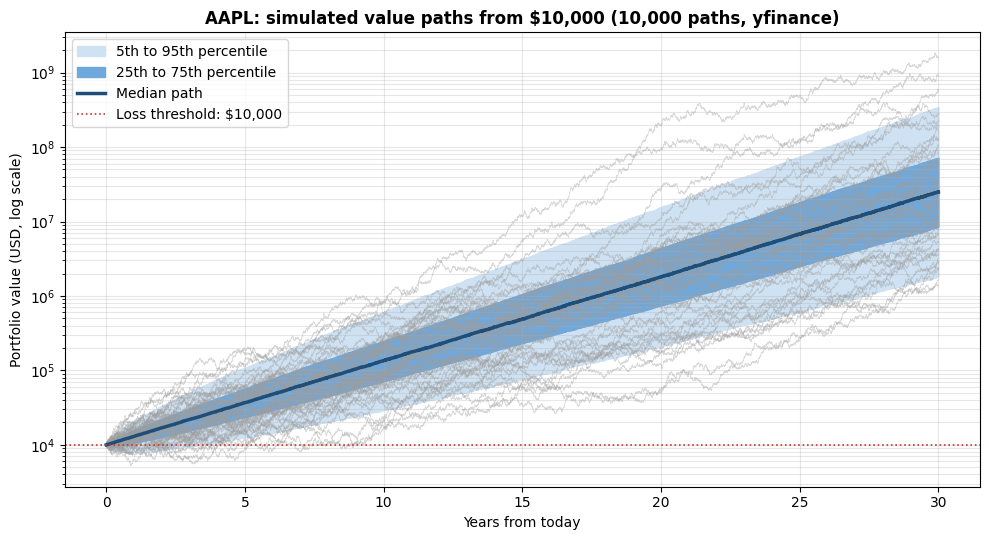

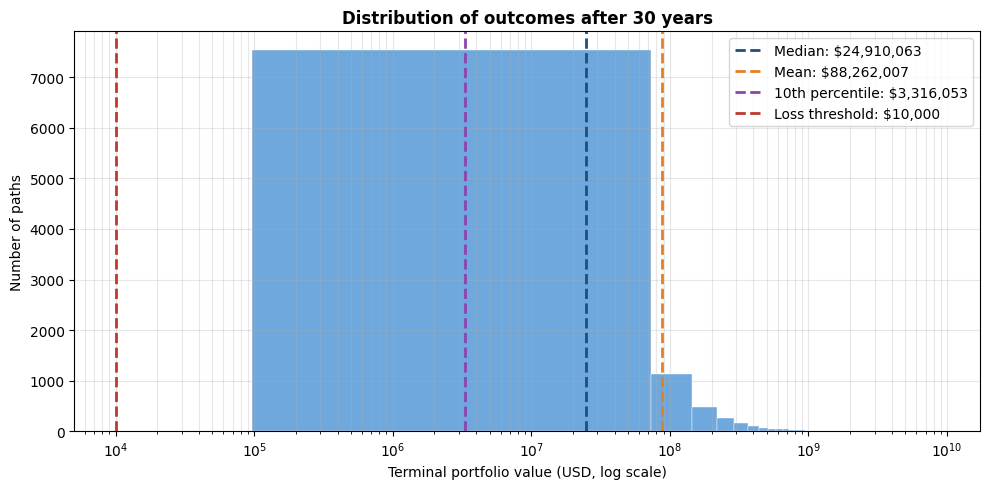

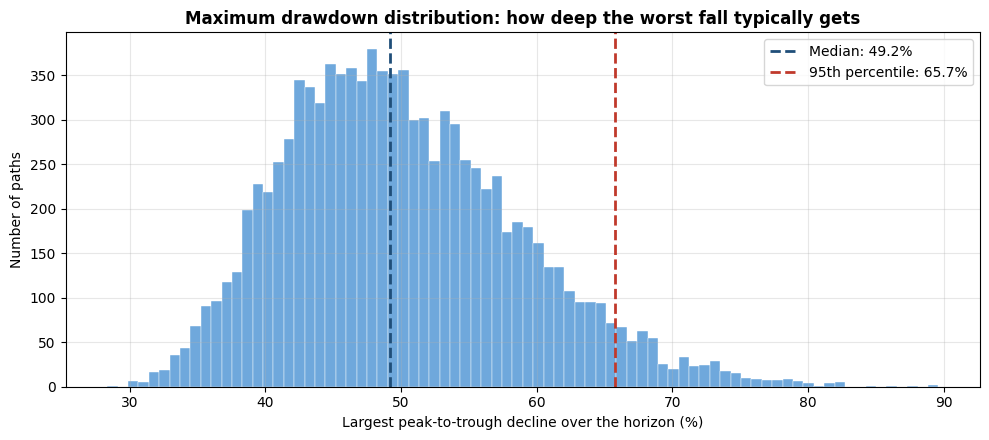

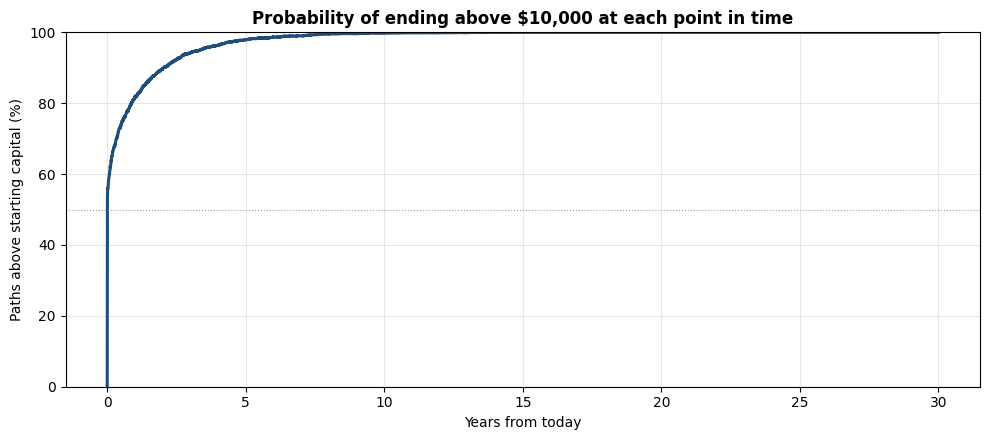

In [6]:
# =============================================================================
# SECTION 6: VISUALIZATIONS
# Four figures for the primary ticker:
#   6a. Fan chart of paths over time (needs the full path matrix)
#   6b. Histogram of terminal values on a log x-axis
#   6c. Histogram of maximum drawdowns
#   6d. Fraction of paths above start_capital over time
# =============================================================================

import numpy as np
import matplotlib.pyplot as plt

# Consistent palette used across all figures
COLORS = {
    "median": "#1f4e79",   # dark blue: median path, median lines
    "band50": "#6fa8dc",   # mid blue: 25th-75th band, histograms
    "band90": "#cfe2f3",   # pale blue: 5th-95th band
    "sample": "#9e9e9e",   # grey: individual sample paths
    "mean":   "#e67e22",   # orange: mean line
    "p10":    "#8e44ad",   # purple: 10th percentile line
    "loss":   "#c0392b",   # red: loss threshold and risk markers
}

# Set once so every figure looks the same
plt.rcParams.update({"font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold"})

ticker_name = c_primary["symbol"]
data_label = c_primary["source"]


# -----------------------------------------------------------------------------
# 6a. Fan chart
# -----------------------------------------------------------------------------
if paths_primary is not None:
    p5, p25, p50, p75, p95 = np.percentile(paths_primary, [5, 25, 50, 75, 95], axis=0)

    fig, ax = plt.subplots(figsize=(10, 5.5))
    for row in paths_primary[:50]:
        ax.plot(time_years, row, color=COLORS["sample"], lw=0.5, alpha=0.4)
    ax.fill_between(time_years, p5, p95, color=COLORS["band90"],
                    label="5th to 95th percentile")
    ax.fill_between(time_years, p25, p75, color=COLORS["band50"],
                    label="25th to 75th percentile")
    ax.plot(time_years, p50, color=COLORS["median"], lw=2.5, label="Median path")
    ax.axhline(loss_threshold, color=COLORS["loss"], lw=1.2, ls=":",
               label=f"Loss threshold: ${loss_threshold:,.0f}")

    ax.set_yscale("log")
    ax.set_xlabel("Years from today")
    ax.set_ylabel("Portfolio value (USD, log scale)")
    ax.set_title(f"{ticker_name}: simulated value paths from ${start_capital:,} "
                 f"({n_paths:,} paths, {data_label})")
    ax.legend(loc="upper left")
    ax.grid(alpha=0.3, which="both")
    plt.tight_layout()
    plt.show()
else:
    print("6a. Fan chart skipped: the run is in chunked mode and the full path matrix "
          "is not stored.")


# -----------------------------------------------------------------------------
# 6b. Terminal value histogram (log x-axis)
# -----------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(terminal, bins=120, color=COLORS["band50"], edgecolor="white", linewidth=0.3)
ax.set_xscale("log")

markers = [
    (median_v, COLORS["median"], "Median"),
    (mean_v, COLORS["mean"], "Mean"),
    (pct_values[10] if 10 in pct_values else np.percentile(terminal, 10),
     COLORS["p10"], "10th percentile"),
    (loss_threshold, COLORS["loss"], "Loss threshold"),
]
for x, color, label in markers:
    ax.axvline(x, color=color, lw=2, ls="--", label=f"{label}: ${x:,.0f}")

ax.set_xlabel("Terminal portfolio value (USD, log scale)")
ax.set_ylabel("Number of paths")
ax.set_title(f"Distribution of outcomes after {years} years")
ax.legend()
ax.grid(alpha=0.3, which="both")
plt.tight_layout()
plt.show()


# -----------------------------------------------------------------------------
# 6c. Maximum drawdown histogram
# -----------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(max_dd * 100, bins=80, color=COLORS["band50"], edgecolor="white", linewidth=0.3)
ax.axvline(dd_median * 100, color=COLORS["median"], lw=2, ls="--",
           label=f"Median: {dd_median:.1%}")
ax.axvline(dd_p95 * 100, color=COLORS["loss"], lw=2, ls="--",
           label=f"95th percentile: {dd_p95:.1%}")

ax.set_xlabel("Largest peak-to-trough decline over the horizon (%)")
ax.set_ylabel("Number of paths")
ax.set_title("Maximum drawdown distribution: how deep the worst fall typically gets")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# -----------------------------------------------------------------------------
# 6d. Probability of being above start_capital over time
# Stored matrix: use it directly. Chunked: recount chunk by chunk.
# -----------------------------------------------------------------------------
if paths_primary is not None:
    prob_above = (paths_primary > start_capital).mean(axis=0)
else:
    rng_prob = np.random.default_rng(seed)
    chunk = max(1000, CHUNK_THRESHOLD // (N_STEPS + 1))
    above_counts = np.zeros(N_STEPS + 1)
    done = 0
    while done < n_paths:
        m = min(chunk, n_paths - done)
        p = simulate_chunk(rng_prob, m, c_primary["growth_step"], c_primary["sigma"])
        above_counts += (p > start_capital).sum(axis=0)
        done += m
    prob_above = above_counts / n_paths

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(time_years, prob_above * 100, color=COLORS["median"], lw=2.2)
ax.axhline(50, color=COLORS["sample"], lw=0.8, ls=":")
ax.set_xlabel("Years from today")
ax.set_ylabel("Paths above starting capital (%)")
ax.set_ylim(0, 100)
ax.set_title(f"Probability of ending above ${start_capital:,} at each point in time")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Diagnostics for AAPL daily log returns (n = 2,511, yfinance data)
  Skewness:                -0.118   (normal = 0)
  Excess kurtosis:         +6.604   (normal = 0)
  Jarque-Bera statistic:   4,568.3
  Jarque-Bera p-value:     0
  Result: normality is REJECTED at the 5% level.

Caution: real returns have fat tails and volatility clustering, so GBM with
normal shocks tends to understate extreme losses. Treat the tail estimates
in Section 5 as optimistic. The student_t option in Section 1 partly addresses
the fat tails but does not model clustering.


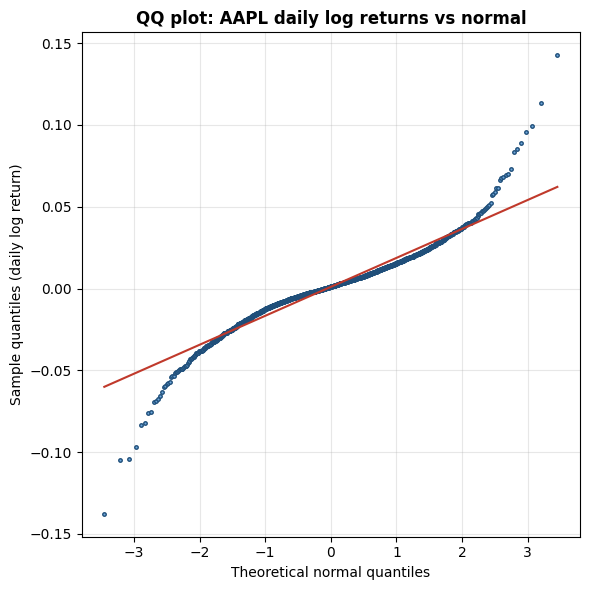

In [7]:
# =============================================================================
# SECTION 7: MODEL DIAGNOSTICS
# Checks whether historical daily log returns look normal, since GBM with
# normal shocks assumes they do.
#   - Jarque-Bera test (skewness and excess kurtosis jointly)
#   - Excess kurtosis (0 for a normal distribution)
#   - QQ plot against a fitted normal
# =============================================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

hist_r = c_primary["hist_log_returns"]

# Jarque-Bera: null hypothesis is that skewness = 0 and excess kurtosis = 0
jb_stat, jb_p = stats.jarque_bera(hist_r)
skew = stats.skew(hist_r)
exc_kurt = stats.kurtosis(hist_r)       # Fisher definition: normal = 0

print(f"Diagnostics for {c_primary['symbol']} daily log returns "
      f"(n = {len(hist_r):,}, {c_primary['source']} data)")
print(f"  Skewness:                {skew:+.3f}   (normal = 0)")
print(f"  Excess kurtosis:         {exc_kurt:+.3f}   (normal = 0)")
print(f"  Jarque-Bera statistic:   {jb_stat:,.1f}")
print(f"  Jarque-Bera p-value:     {jb_p:.3g}")
if jb_p < 0.05:
    print("  Result: normality is REJECTED at the 5% level.")
else:
    print("  Result: normality is not rejected at the 5% level.")
print()
print("Caution: real returns have fat tails and volatility clustering, so GBM with")
print("normal shocks tends to understate extreme losses. Treat the tail estimates")
print("in Section 5 as optimistic. The student_t option in Section 1 partly addresses")
print("the fat tails but does not model clustering.")

# QQ plot: points on the diagonal mean the returns look normal.
# Curvature at the ends indicates heavier tails than a normal distribution.
fig, ax = plt.subplots(figsize=(6, 6))
stats.probplot(hist_r, dist="norm", plot=ax)
ax.get_lines()[0].set_markersize(2.5)
ax.get_lines()[0].set_markerfacecolor(COLORS["band50"])
ax.get_lines()[0].set_markeredgecolor(COLORS["median"])
ax.get_lines()[1].set_color(COLORS["loss"])
ax.set_title(f"QQ plot: {c_primary['symbol']} daily log returns vs normal")
ax.set_xlabel("Theoretical normal quantiles")
ax.set_ylabel("Sample quantiles (daily log return)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
# =============================================================================
# SECTION 8: MULTI-TICKER COMPARISON (extension)
# Runs the same simulation for every ticker, each with its own seed offset,
# so comparisons are fair and the draws are independent across tickers.
# Produces one summary table and an overlaid chart of median paths.
# =============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def run_ticker(c, seed_offset):
    """
    Simulate one ticker and return its terminal values, drawdowns, and
    (when the matrix fits in memory) its median path.
    """
    rng_t = np.random.default_rng(seed + seed_offset)
    chunk = max(1000, CHUNK_THRESHOLD // (N_STEPS + 1))
    term_parts, dd_parts = [], []
    median_path = None

    if not uses_chunks:
        p = simulate_chunk(rng_t, n_paths, c["growth_step"], c["sigma"])
        term_parts.append(p[:, -1])
        dd_parts.append(max_drawdown_per_path(p))
        median_path = np.median(p, axis=0)
    else:
        done = 0
        while done < n_paths:
            m = min(chunk, n_paths - done)
            p = simulate_chunk(rng_t, m, c["growth_step"], c["sigma"])
            term_parts.append(p[:, -1])
            dd_parts.append(max_drawdown_per_path(p))
            done += m

    return np.concatenate(term_parts), np.concatenate(dd_parts), median_path


if len(tickers) > 1:
    rows = []
    fig, ax = plt.subplots(figsize=(10, 5.5))
    palette = plt.get_cmap("tab10")

    for i, t in enumerate(tickers):
        c = calib[t]
        term_t, dd_t, med_path = run_ticker(c, seed_offset=i)

        rows.append({
            "Ticker": t,
            "Data source": c["source"],
            "Median terminal ($)": np.median(term_t),
            "10th percentile ($)": np.percentile(term_t, 10),
            "Chance of loss": (term_t < loss_threshold).mean(),
            "Median max drawdown": np.median(dd_t),
        })

        if med_path is not None:
            ax.plot(time_years, med_path, lw=2.2, color=palette(i), label=t)

    if any(r is not None for r in [True]) and len(ax.get_lines()) > 0:
        ax.set_yscale("log")
        ax.axhline(loss_threshold, color=COLORS["loss"], lw=1.2, ls=":",
                   label=f"Loss threshold: ${loss_threshold:,.0f}")
        ax.set_xlabel("Years from today")
        ax.set_ylabel("Median portfolio value (USD, log scale)")
        ax.set_title(f"Median paths by ticker, starting from ${start_capital:,}")
        ax.legend()
        ax.grid(alpha=0.3, which="both")
        plt.tight_layout()
        plt.show()
    else:
        plt.close(fig)
        print("Median-path chart skipped: the run is in chunked mode.")

    cmp_df = pd.DataFrame(rows).set_index("Ticker")
    print("Comparison across tickers")
    print(cmp_df.to_string(float_format=lambda x: f"{x:,.3f}"))
    print()
    print("Each ticker uses its own seed offset, so the random draws differ between "
          "tickers. Differences in the table reflect the estimated drift and volatility, "
          "plus sampling noise.")
else:
    print("Single ticker: comparison section skipped.")

Single ticker: comparison section skipped.


Sensitivity grid: 9 cells x 5,000 paths in 23.61s
Base case: mu = 30.24%, sigma = 29.11%


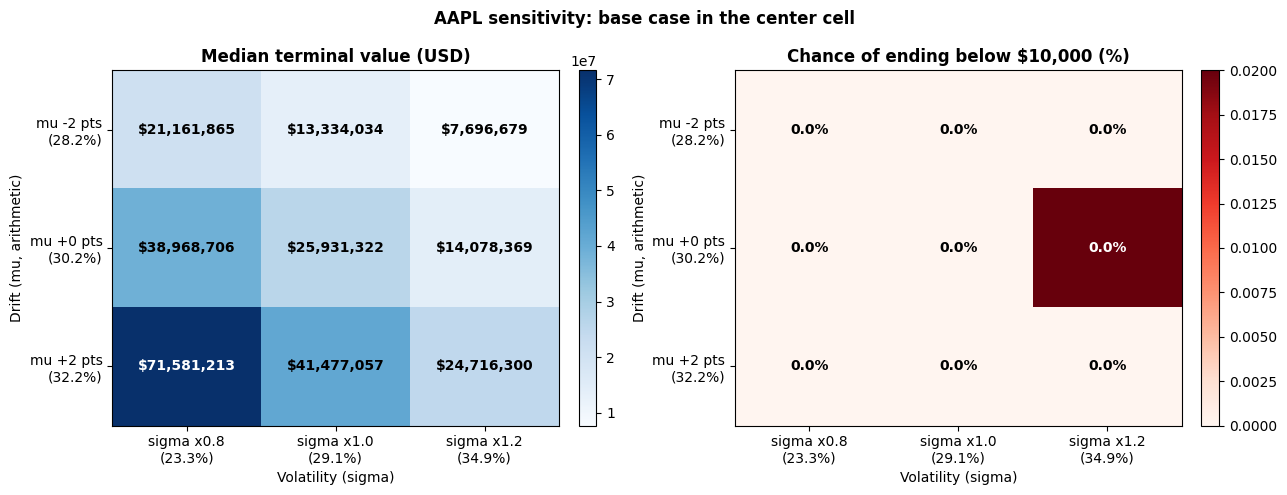

Center cell (base case): median $25,931,322, chance of loss 0.0%
Full-run median from Section 5 for comparison: $24,910,063


In [9]:
# =============================================================================
# SECTION 9: SENSITIVITY ANALYSIS (extension)
# Model estimates are uncertain. This grid varies volatility and drift around
# the calibrated values to show how much the conclusions depend on them.
#   - sigma: calibrated value times 0.8, 1.0, 1.2
#   - mu:    calibrated value plus -2, 0, +2 percentage points
# Each cell is simulated with a fixed, smaller path count (sens_paths) to keep
# runtime reasonable. Each cell has its own seed, so results are reproducible.
# =============================================================================

import time
import numpy as np
import matplotlib.pyplot as plt

sens_paths = min(n_paths, 5_000)          # paths per grid cell
sig_mult = [0.8, 1.0, 1.2]                # multipliers on calibrated sigma
mu_shift = [-0.02, 0.0, 0.02]             # additive shifts to calibrated mu

base_mu = c_primary["mu_arith"]
base_sigma = c_primary["sigma"]

med_grid = np.zeros((len(mu_shift), len(sig_mult)))
loss_grid = np.zeros((len(mu_shift), len(sig_mult)))

t0 = time.perf_counter()
for i, d_mu in enumerate(mu_shift):
    for j, m_sig in enumerate(sig_mult):
        sig = base_sigma * m_sig
        mu = base_mu + d_mu

        # Same volatility-drag correction as Section 2
        g_step = (mu - sig**2 / 2) / steps_per_year

        # Distinct seed per cell so cells are independent but reproducible
        rng_cell = np.random.default_rng(seed + 1000 + 10 * i + j)
        p = simulate_chunk(rng_cell, sens_paths, g_step, sig)
        term = p[:, -1]

        med_grid[i, j] = np.median(term)
        loss_grid[i, j] = (term < loss_threshold).mean()

print(f"Sensitivity grid: {len(mu_shift) * len(sig_mult)} cells x {sens_paths:,} paths "
      f"in {time.perf_counter() - t0:.2f}s")
print(f"Base case: mu = {base_mu:.2%}, sigma = {base_sigma:.2%}")

# -----------------------------------------------------------------------------
# Heatmaps
# -----------------------------------------------------------------------------
x_labels = [f"sigma x{m:.1f}\n({base_sigma * m:.1%})" for m in sig_mult]
y_labels = [f"mu {d * 100:+.0f} pts\n({(base_mu + d):.1%})" for d in mu_shift]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

panels = [
    (axes[0], med_grid, "Median terminal value (USD)", "Blues", "${:,.0f}"),
    (axes[1], loss_grid * 100, f"Chance of ending below ${loss_threshold:,.0f} (%)",
     "Reds", "{:.1f}%"),
]
for ax, grid, title, cmap, fmt in panels:
    im = ax.imshow(grid, cmap=cmap, aspect="auto")
    ax.set_xticks(range(len(sig_mult)), x_labels)
    ax.set_yticks(range(len(mu_shift)), y_labels)
    ax.set_xlabel("Volatility (sigma)")
    ax.set_ylabel("Drift (mu, arithmetic)")
    ax.set_title(title)

    # Write each value in its cell, using dark text on light cells and white on dark
    lo, hi = grid.min(), grid.max()
    for i in range(grid.shape[0]):
        for j in range(grid.shape[1]):
            norm_val = (grid[i, j] - lo) / (hi - lo) if hi > lo else 0.5
            color = "white" if norm_val > 0.6 else "black"
            ax.text(j, i, fmt.format(grid[i, j]), ha="center", va="center",
                    fontsize=10, color=color, fontweight="bold")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.suptitle(f"{c_primary['symbol']} sensitivity: base case in the center cell",
             fontweight="bold")
plt.tight_layout()
plt.show()

# Center cell should match the base case (up to sampling noise)
center_med = med_grid[1, 1]
center_loss = loss_grid[1, 1]
print(f"Center cell (base case): median ${center_med:,.0f}, chance of loss {center_loss:.1%}")
print(f"Full-run median from Section 5 for comparison: ${np.median(terminal):,.0f}")

In [10]:
# =============================================================================
# SECTION 10: PLAIN-LANGUAGE SUMMARY
# A short summary generated from the computed numbers (f-strings, not fixed
# text). It covers the typical outcome, the bad case at the 10th percentile,
# the chance of ending below the starting capital, the typical worst drawdown,
# and a reminder about what the model does and does not say.
# =============================================================================

import numpy as np

# Chance of ending below the starting capital. This is separate from
# loss_threshold, which the user may have set to a different level.
p_below_start = (terminal < start_capital).mean()

median_v = S["median"]
p10_v = S["percentiles"][10] if 10 in S["percentiles"] else np.percentile(terminal, 10)
dd_med = S["dd_median"]
cagr = S["cagr_median"]

summary_text = (
    f"**Typical outcome.** A ${start_capital:,} investment in {c_primary['symbol']} "
    f"has a median value of ${median_v:,.0f} after {years} years, which is an implied "
    f"annual growth rate of {cagr:.1%}. "
    f"**Bad case.** In the 10th-percentile scenario, the value falls to "
    f"${p10_v:,.0f}. "
    f"**Chance of loss.** The model gives a {p_below_start:.1%} chance of ending below "
    f"the starting ${start_capital:,}. "
    f"**Drawdowns.** The typical worst peak-to-trough decline along the way is "
    f"{dd_med:.0%} of the peak value. "
    f"**Limits of the model.** These figures assume that the past statistical behavior "
    f"of {c_primary['symbol']} continues. They are an illustration of randomness "
    f"under stated assumptions, not a price forecast."
)

try:
    from IPython.display import Markdown, display
    display(Markdown(summary_text))
except ImportError:
    print(summary_text)

**Typical outcome.** A $10,000 investment in AAPL has a median value of $24,910,063 after 30 years, which is an implied annual growth rate of 29.8%. **Bad case.** In the 10th-percentile scenario, the value falls to $3,316,053. **Chance of loss.** The model gives a 0.0% chance of ending below the starting $10,000. **Drawdowns.** The typical worst peak-to-trough decline along the way is 49% of the peak value. **Limits of the model.** These figures assume that the past statistical behavior of AAPL continues. They are an illustration of randomness under stated assumptions, not a price forecast.